# Predicting tourist arrivals to Sri Lanka

I predict monthly arrivals by origin market to help plan staff and transport. I combined nine official [SLTDA tables](https://www.sltda.gov.lk/en/tourist-arrivals-from-all-countries) from 2018 to September 2026. I corrected clear country-name differences, kept zeros and removed unresolved entries and rows with missing history. Monthly totals match the source, but some country labels may still need review.

The CSV has 17,053 rows from January 2019 to September 2026. Each row is one market in one month. The inputs are market, month and arrivals 1, 2, 3 and 12 months earlier. `Arrivals` is the target. `Year_Month` labels the period. The 2018 counts supply the first annual lag.

## Setup
Run the cells in order. In Colab, upload `Tourism_Arrivals.csv` when asked. The extra model packages are only needed for this notebook.

In [ ]:
%pip install -q pandas numpy matplotlib "scikit-learn>=1.4" catboost lightgbm shap lime

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

csv_file = next((path for path in [Path('../data/Tourism_Arrivals.csv'),
                                 Path('data/Tourism_Arrivals.csv'),
                                 Path('Tourism_Arrivals.csv')] if path.exists()), None)
if csv_file is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place Tourism_Arrivals.csv in data/ or beside the notebook.')
    files.upload()
    csv_file = Path('Tourism_Arrivals.csv')

data = pd.read_csv(csv_file)
data['Month'] = pd.PeriodIndex(data.Year_Month, freq='M')
features = ['Country', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'month_number']
random_seed = 42

assert not data.isna().any().any()
assert not data.duplicated(['Year_Month', 'Country']).any()
assert data[[column for column in features if column != 'Country'] + ['Arrivals']].ge(0).all().all()
display(data.head())

,Year_Month,Country,lag_1,lag_2,lag_3,lag_12,month_number,Arrivals,Month
0,2019-01,Afghanistan,72,52,41,83,1,49,2019-01
1,2019-01,Albania,31,12,13,14,1,48,2019-01
2,2019-01,Algeria,43,27,20,38,1,34,2019-01
3,2019-01,Andorra,4,1,3,4,1,2,2019-01
4,2019-01,Angola,1,1,1,0,1,4,2019-01


## Exploration and time split

I train on 2019–2023 and compare on 2024. Four markets without training examples are left out. To choose settings, I train through 2022 and check 2023.

Months stay in time order to match future forecasting. A random split could train on later months and test earlier ones. The 2025–September 2026 period was already examined, so it is not an untouched final test.

Origins without training examples: ['Aruba', 'Central African Republic', 'Guinea', 'Palau']
Training rows: 10811 | validation rows: 2207


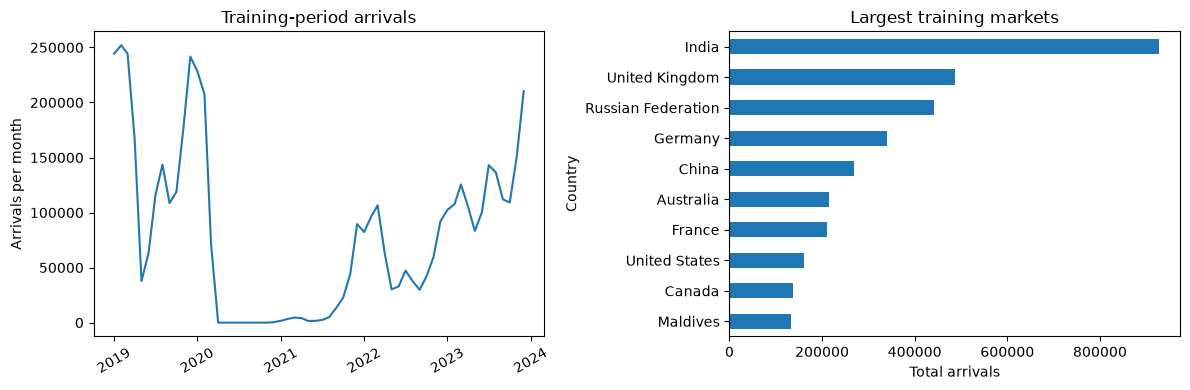

,Arrivals
count,10811.000000
mean,446.107853
std,2252.160959
min,0.000000
25%,0.000000
50%,3.000000
75%,72.000000
max,48442.000000


In [2]:
train_data = data.loc[data.Month.dt.year.between(2019, 2023)].copy()
validation_data = data.loc[data.Month.dt.year.eq(2024)].copy()
known_countries = set(train_data.Country)
print('Origins without training examples:', sorted(set(validation_data.Country) - known_countries))
validation_data = validation_data.loc[validation_data.Country.isin(known_countries)].copy()

assert train_data.Month.max() < validation_data.Month.min()
print('Training rows:', len(train_data), '| validation rows:', len(validation_data))

monthly_arrivals = train_data.groupby('Month').Arrivals.sum()
top_markets = train_data.groupby('Country').Arrivals.sum().nlargest(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly_arrivals.index.to_timestamp(), monthly_arrivals.to_numpy())
axes[0].set(title='Training-period arrivals', ylabel='Arrivals per month')
axes[0].tick_params(axis='x', labelrotation=30)
top_markets.sort_values().plot.barh(ax=axes[1], title='Largest training markets')
axes[1].set_xlabel('Total arrivals')

plt.tight_layout()
plt.show()
display(train_data.Arrivals.describe().to_frame())

## Why Extra Trees

Extra Trees can learn relationships between market, season and recent counts. It averages trees that try random split thresholds. A standard tree searches for the best threshold. Here every tree uses all training rows and encoded features; Random Forest uses bootstrap samples by default.

I found no named Extra Trees coverage in the supplied course materials. It trains quickly and works with SHAP and LIME, so I chose it as the new algorithm to study. Other models may predict better.

I compare two settings per model using 2023 MAE. Tree counts and the seed stay fixed. Most models use one-hot encoding; CatBoost handles market and month as categories.

In [3]:
def build_pipeline(model):
    # Fit preprocessing on the training data only.
    preprocessing = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         ['Country', 'month_number']),
        ('history', StandardScaler(), ['lag_1', 'lag_2', 'lag_3', 'lag_12'])])
    return make_pipeline(preprocessing, model)


def make_model(name, settings):
    if name == 'Extra Trees':
        return build_pipeline(ExtraTreesRegressor(n_estimators=150, max_features=1.0,
            bootstrap=False, random_state=random_seed, n_jobs=4, **settings))
    if name == 'Random Forest':
        return build_pipeline(RandomForestRegressor(n_estimators=150,
            random_state=random_seed, n_jobs=4, **settings))
    if name == 'Bagged trees':
        tree = DecisionTreeRegressor(random_state=random_seed, **settings)
        return build_pipeline(BaggingRegressor(estimator=tree, n_estimators=150,
            max_samples=.8, bootstrap=True, random_state=random_seed, n_jobs=2))
    if name == 'CatBoost':
        return CatBoostRegressor(iterations=400, learning_rate=.05, l2_leaf_reg=5,
            loss_function='RMSE', cat_features=['Country', 'month_number'],
            random_seed=random_seed, thread_count=4, verbose=False,
            allow_writing_files=False, **settings)
    if name == 'LightGBM':
        return build_pipeline(LGBMRegressor(n_estimators=400, learning_rate=.05,
            min_child_samples=30, reg_lambda=10, random_state=random_seed,
            n_jobs=4, verbosity=-1, deterministic=True, force_col_wise=True, **settings))
    raise ValueError(name)


def model_inputs(name, frame):
    inputs = frame[features].copy()
    if name == 'CatBoost':
        inputs['Country'] = inputs.Country.astype(str)
        inputs['month_number'] = inputs.month_number.astype(str)
    return inputs


def predict_model(name, model, frame):
    if name == 'Voting ensemble':
        # Average the three fitted models without cloning CatBoost.
        values = np.mean([predict_model(base, fitted, frame)
                          for base, fitted in model.items()], axis=0)
    else:
        values = model.predict(model_inputs(name, frame))
    return np.maximum(0, values)


def calculate_scores(actual, prediction):
    error = np.asarray(actual) - np.asarray(prediction)
    return {'MAE': np.abs(error).mean(), 'RMSE': root_mean_squared_error(actual, prediction),
            'R2': r2_score(actual, prediction),
            'WAPE_pct': 100 * np.abs(error).sum() / np.sum(actual)}


tuning_train = train_data.loc[train_data.Month.dt.year.le(2022)]
tuning_check = train_data.loc[train_data.Month.dt.year.eq(2023)]
options = {
    'Extra Trees': [{'max_depth': 8, 'min_samples_leaf': 10},
                    {'max_depth': 12, 'min_samples_leaf': 5}],
    'Random Forest': [{'max_depth': 12, 'min_samples_leaf': 5},
                      {'max_depth': 20, 'min_samples_leaf': 2}],
    'Bagged trees': [{'max_depth': 8, 'min_samples_leaf': 10},
                     {'max_depth': 12, 'min_samples_leaf': 5}],
    'CatBoost': [{'depth': 4}, {'depth': 6}],
    'LightGBM': [{'num_leaves': 15}, {'num_leaves': 31}]}
selected, tuning_rows = {}, []
for name, candidates in options.items():
    errors = []
    for settings in candidates:
        model = make_model(name, settings).fit(model_inputs(name, tuning_train), tuning_train.Arrivals)
        error = mean_absolute_error(tuning_check.Arrivals, predict_model(name, model, tuning_check))
        errors.append(error)
        tuning_rows.append({'Model': name, 'Settings': str(settings), '2023 MAE': error})
    selected[name] = candidates[int(np.argmin(errors))]

display(pd.DataFrame(tuning_rows).round(3))

,Model,Settings,2023 MAE
0,Extra Trees,"{'max_depth': 8, 'min_samples_leaf': 10}",226.530
1,Extra Trees,"{'max_depth': 12, 'min_samples_leaf': 5}",228.300
2,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 5}",247.767
3,Random Forest,"{'max_depth': 20, 'min_samples_leaf': 2}",241.424
4,Bagged trees,"{'max_depth': 8, 'min_samples_leaf': 10}",251.940
5,Bagged trees,"{'max_depth': 12, 'min_samples_leaf': 5}",248.396
6,CatBoost,{'depth': 4},245.811
7,CatBoost,{'depth': 6},267.612
8,LightGBM,{'num_leaves': 15},242.269
9,LightGBM,{'num_leaves': 31},249.519


## Models and simple comparison rules

MAE is average error in arrivals. RMSE gives more weight to large errors. WAPE is total absolute error divided by total actual arrivals, as a percentage. R² describes explained variation, not percentage accuracy.

The two **baselines are simple rules, not trained ML algorithms**. One predicts the previous month's count. The other predicts the same month last year. They show whether training a model helps more than repeating a known count.

Voting averages Random Forest, CatBoost and LightGBM equally. Its base models use the first settings listed above. The other models use the settings chosen on 2023.

In [4]:
def fit_models(training):
    fitted = {name: make_model(name, settings).fit(model_inputs(name, training), training.Arrivals)
              for name, settings in selected.items()}
    fitted['Voting ensemble'] = {
        name: make_model(name, options[name][0]).fit(model_inputs(name, training), training.Arrivals)
        for name in ['Random Forest', 'CatBoost', 'LightGBM']}
    return fitted


def compare_models(fitted, frame):
    estimates = {name: predict_model(name, model, frame) for name, model in fitted.items()}
    estimates['Previous-month baseline'] = frame.lag_1.to_numpy()
    estimates['Seasonal baseline'] = frame.lag_12.to_numpy()
    return pd.DataFrame({name: calculate_scores(frame.Arrivals, prediction)
                         for name, prediction in estimates.items()}).T.sort_values('MAE')


models = fit_models(train_data)
comparison = compare_models(models, validation_data)
chosen_name = 'Extra Trees'
display(comparison.round(3))


def predict_arrivals(frame):
    return predict_model(chosen_name, models[chosen_name], frame)

,MAE,RMSE,R2,WAPE_pct
Voting ensemble,227.099,919.955,0.934,24.409
CatBoost,232.301,873.159,0.941,24.969
Random Forest,235.840,941.069,0.931,25.349
Bagged trees,240.605,1008.358,0.921,25.861
LightGBM,252.439,1005.557,0.921,27.133
Extra Trees,258.393,1111.300,0.904,27.773
Previous-month baseline,286.449,1128.716,0.901,30.789
Seasonal baseline,301.611,1264.596,0.876,32.418


Voting has the lowest MAE, **227.10**, about **12.1% below** Extra Trees at **258.39**. CatBoost has the highest R², **0.941**. Extra Trees remains the new algorithm studied, although other models perform better.

## Errors by market
I compare errors for each market with the previous-month baseline. An overall score can hide large errors for individual markets.


Origins beating the previous-month baseline: 57 / 184


,actual,MAE,baseline_MAE
Country,,,
India,416974,6451.95,6643.50
Russian Federation,201920,6271.91,5300.42
United Kingdom,178339,3786.11,4656.83
Germany,136084,2665.66,2793.83
China,131681,2132.71,2414.67
Australia,89573,1238.61,1743.50
France,88775,2062.57,2633.58
United States,59532,935.07,1419.17
Netherlands,50116,1499.71,1978.08


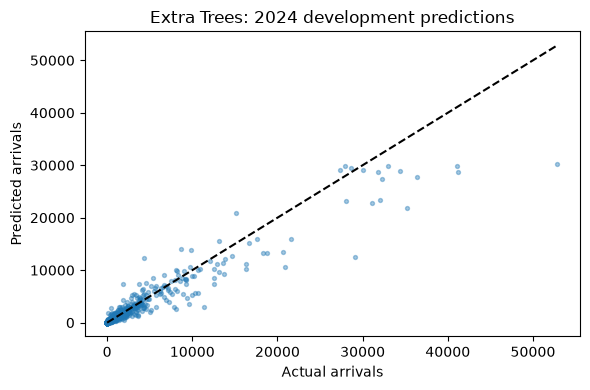

In [5]:
results = validation_data[['Month', 'Country', 'Arrivals', 'lag_1']].copy()
results['Prediction'] = predict_arrivals(validation_data)
results['Error'] = np.abs(results.Arrivals - results.Prediction)
results['Baseline_error'] = np.abs(results.Arrivals - results.lag_1)

market_errors = results.groupby('Country').agg(
    actual=('Arrivals', 'sum'), MAE=('Error', 'mean'), baseline_MAE=('Baseline_error', 'mean'))
print('Origins beating the previous-month baseline:',
      int((market_errors.MAE < market_errors.baseline_MAE).sum()), '/', len(market_errors))
display(market_errors.sort_values('actual', ascending=False).head(10).round(2))

plt.figure(figsize=(6, 4))
plt.scatter(results.Arrivals, results.Prediction, s=8, alpha=.4)
limit = max(results.Arrivals.max(), results.Prediction.max())
plt.plot([0, limit], [0, limit], 'k--')
plt.xlabel('Actual arrivals')
plt.ylabel('Predicted arrivals')
plt.title(f'{chosen_name}: 2024 development predictions')
plt.tight_layout()
plt.show()


## Later-period test

I train the same settings through 2024 and check January 2025–September 2026. Only known markets are included. This period was examined before, so it is not an independent final test. Each prediction uses actual earlier counts.

In [6]:
assessment_train = data.loc[data.Month.dt.year.between(2019, 2024)].copy()
assessment_data = data.loc[data.Month.dt.year.ge(2025)].copy()
assessment_data = assessment_data.loc[assessment_data.Country.isin(assessment_train.Country.unique())]
assessment_models = fit_models(assessment_train)
assessment_comparison = compare_models(assessment_models, assessment_data)
print('Retrospective train rows:', len(assessment_train), '| test rows:', len(assessment_data))
display(assessment_comparison.round(3))

Retrospective train rows: 13066 | test rows: 3978


,MAE,RMSE,R2,WAPE_pct
Seasonal baseline,219.670,972.141,0.947,21.544
Random Forest,238.997,1089.767,0.933,23.439
Voting ensemble,246.638,1173.814,0.922,24.189
Bagged trees,252.486,1163.063,0.924,24.762
LightGBM,265.794,1269.968,0.909,26.067
CatBoost,268.480,1214.140,0.917,26.331
Extra Trees,293.354,1365.022,0.895,28.770
Previous-month baseline,299.554,1175.899,0.922,29.378


Extra Trees has MAE **293.35**, tuned Random Forest **239.00**, and the same-month-last-year rule **219.67**. The simple yearly rule performs better here.

## Three-month outlook

The app predicts up to three months. I check January, April, July and October 2024 starting points using models trained through 2023. Later steps use earlier predictions where actual counts would not yet be known. Last year's matching count stays actual history.

In [7]:
history = data.set_index(['Country', 'Month']).Arrivals
horizon_rows = []

for name in list(models) + ['Previous-month baseline', 'Seasonal baseline']:
    for start_month in [pd.Period(year=2024, month=m, freq='M') for m in [1, 4, 7, 10]]:
        forecast_values = {}
        for step in range(3):
            target_month = start_month + step
            batch = []
            for country in sorted(known_countries):
                inputs = {'Country': country, 'month_number': target_month.month}
                for lag in [1, 2, 3, 12]:
                    earlier_month = target_month - lag
                    key = (country, earlier_month)
                    # Do not feed future actual counts into the forecast.
                    inputs[f'lag_{lag}'] = (forecast_values.get(key) if earlier_month >= start_month
                                           else history.get(key))
                if all(pd.notna(value) for value in inputs.values()):
                    batch.append(inputs)
            frame = pd.DataFrame(batch)
            if name == 'Previous-month baseline':
                estimates = frame.lag_1.to_numpy()
            elif name == 'Seasonal baseline':
                estimates = frame.lag_12.to_numpy()
            else:
                estimates = predict_model(name, models[name], frame)
            for country, estimate in zip(frame.Country, estimates):
                forecast_values[(country, target_month)] = estimate
                actual = history.get((country, target_month))
                if pd.notna(actual):
                    horizon_rows.append([name, step + 1, actual, estimate])

horizon_check = pd.DataFrame(horizon_rows, columns=['Model', 'Horizon', 'Actual', 'Prediction'])
horizon_scores = pd.DataFrame([
    {'Model': name, 'Months ahead': horizon, 'Cases': len(group),
     **calculate_scores(group.Actual, group.Prediction)}
    for (name, horizon), group in horizon_check.groupby(['Model', 'Horizon'])])
display(horizon_scores.pivot(index='Model', columns='Months ahead', values='MAE').round(2))

Months ahead,1,2,3
Model,,,
Bagged trees,281.96,329.35,359.50
CatBoost,273.38,331.89,341.72
Extra Trees,286.69,353.78,386.80
LightGBM,258.97,334.83,366.94
Previous-month baseline,351.47,463.25,484.00
Random Forest,280.42,320.50,344.91
Seasonal baseline,349.45,322.34,266.50
Voting ensemble,257.85,304.05,324.27


Extra Trees MAE rises from **286.69** to **353.78** and **386.80**. At three months, voting gives **324.27**, while the yearly rule gives **266.50**. These checks do not test the app model trained through September 2026.

## SHAP explanation
I use 40 training rows as background and explain 40 sampled validation cases plus India in January 2024. This is the first validation month for the largest training market.


SHAP sum: 28951.15 | model: 28951.15 | gap: 0.0


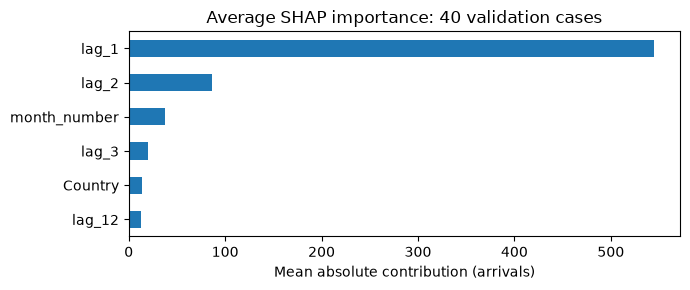

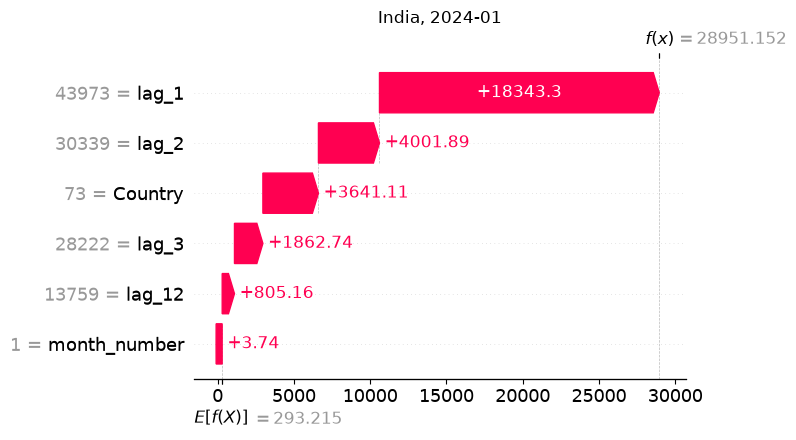

In [8]:
import shap
from lime.lime_tabular import LimeTabularExplainer

countries = sorted(train_data.Country.unique())
country_codes = {country: index for index, country in enumerate(countries)}

def encode(frame):
    values = frame[features].copy()
    values['Country'] = values.Country.map(country_codes)
    return values.to_numpy(dtype=float)

# The explainers use numeric country codes; the predictor needs the names back.
def explain_prediction(array):
    frame = pd.DataFrame(np.atleast_2d(array), columns=features)
    frame['Country'] = [countries[index] for index in np.rint(frame.Country).astype(int)]
    return predict_arrivals(frame)

background = encode(train_data.sample(40, random_state=random_seed))
largest_market = train_data.groupby('Country').Arrivals.sum().idxmax()
example = validation_data.loc[validation_data.Country.eq(largest_market)].head(1)
sample = validation_data.sample(40, random_state=random_seed)
explanation_rows = pd.concat([example, sample]).drop_duplicates(['Month', 'Country'])

explainer = shap.Explainer(explain_prediction, shap.maskers.Independent(background),
                           algorithm='permutation', feature_names=features, seed=random_seed)
shap_values = explainer(encode(explanation_rows), max_evals=65)
importance = pd.Series(np.abs(shap_values.values[1:]).mean(axis=0), index=features).sort_values()
importance.plot.barh(figsize=(7, 3), title='Average SHAP importance: 40 validation cases')
plt.xlabel('Mean absolute contribution (arrivals)')
plt.tight_layout()
plt.show()

shap.plots.waterfall(shap_values[0], max_display=len(features), show=False)
plt.title(f'{example.Country.iloc[0]}, {example.Month.iloc[0]}')
plt.tight_layout()
plt.show()
model_prediction = float(predict_arrivals(example)[0])
shap_prediction = float(shap_values.base_values[0] + shap_values.values[0].sum())
print('SHAP sum:', round(shap_prediction, 2), '| model:', round(model_prediction, 2),
      '| gap:', round(abs(shap_prediction - model_prediction), 3))

## LIME explanation
LIME fits a simple model near the same prediction. Its local R² and prediction gap show how closely it matches Extra Trees for this case.


Local surrogate R²: 0.936
Surrogate prediction: 27216.46 | model: 28951.15 | gap: -1734.7


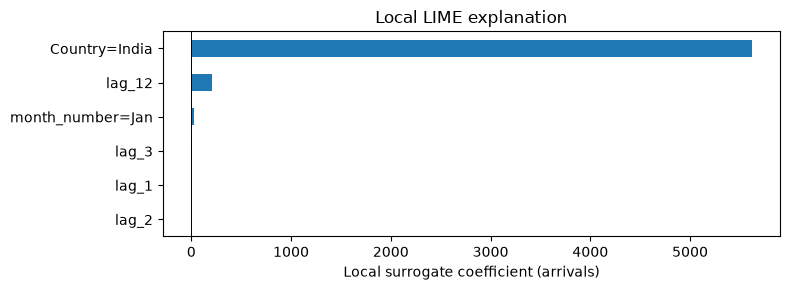

In [9]:
month_names = ['unused', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_column = features.index('month_number')
lime_explainer = LimeTabularExplainer(
    encode(train_data), feature_names=features, mode='regression',
    categorical_features=[0, month_column], categorical_names={0: countries, month_column: month_names},
    discretize_continuous=False, sample_around_instance=True,
    kernel_width=1.0, random_state=random_seed)
lime_result = lime_explainer.explain_instance(
    encode(example)[0], explain_prediction, num_features=len(features), num_samples=3000)

weights = pd.Series(dict(lime_result.as_list())).sort_values()
weights.plot.barh(figsize=(8, 3), color=['tab:red' if weight < 0 else 'tab:blue' for weight in weights])
plt.axvline(0, color='black', linewidth=.7)
plt.title('Local LIME explanation')
plt.xlabel('Local surrogate coefficient (arrivals)')
plt.tight_layout()
plt.show()

# Check how closely the local model matches Extra Trees.
print('Local surrogate R²:', round(float(lime_result.score), 3))
print('Surrogate prediction:', round(float(lime_result.local_pred[0]), 2),
      '| model:', round(model_prediction, 2),
      '| gap:', round(float(lime_result.local_pred[0] - model_prediction), 2))

For India in January 2024, Extra Trees predicts **28,951** arrivals against **34,399** actual arrivals. The previous-month count has the largest SHAP contribution, about **+18,343** relative to the background. The base value and contributions add up to the prediction.

LIME has local R² **0.936** and predicts about **1,735** fewer arrivals than Extra Trees. Neither method proves cause and effect. Changing related lags separately can create unrealistic inputs.


## Example prediction
These are the inputs and result for the same validation example.


In [10]:
display(example[features])
display(pd.DataFrame({
    'Month': [str(example.Month.iloc[0])], 'Country': [example.Country.iloc[0]],
    'Predicted_arrivals': [round(float(predict_arrivals(example)[0]))],
    'Observed_arrivals': [int(example.Arrivals.iloc[0])]}))

,Country,lag_1,lag_2,lag_3,lag_12,month_number
10883,India,43973,30339,28222,13759,1


,Month,Country,Predicted_arrivals,Observed_arrivals
0,2024-01,India,28951,34399


## Limitations and ethical use
Extra Trees beats the previous-month baseline for only **57 of 184 markets**. The seasonal rule is stronger in the later check and at longer horizons. There is no single best result across all markets and periods.

The data contains public totals, not personal travel records. Country labels, revisions and missing history can affect results. Errors could lead to poor budget decisions, so forecasts need human review.

Flight capacity, exchange rates and travel restrictions are not included. Sudden changes can affect demand, and no prediction interval is available.


## Conclusion

Extra Trees gives a working forecast, but other ensembles have lower 2024 error. The yearly rule is stronger in the later check and at longer lead times. I would keep settings fixed and check new months before using the forecasts for planning.

The app uses the same Extra Trees settings, trained on all eligible rows through September 2026. It has not been tested on new data.

Sources: [SLTDA](https://www.sltda.gov.lk/en/tourist-arrivals-from-all-countries), [Extra Trees paper](https://doi.org/10.1007/s10994-006-6226-1), [implementation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html).